# What Does a Forecast Need to Know?
### Forecasting Black Week sales with regressors

**The situation:** an online shop selling consumer electronics is preparing for Black Week 2026 (23–30 November). Stock has to be ordered weeks in advance, so the planning team needs to know: **how many units of each product will we sell?**

**My approach:** I start with a forecast that only knows past sales. Then I give it one extra piece of information at a time, and measure how much each piece improves the forecast. At the end, I turn the best version into a demand plan the planning team can actually use.

These extra pieces of information are called **regressors**.

### A note on the data

The data is **synthetic**: I generated it myself. The shop, the products and the numbers are fictional.

I did this on purpose. Because I built the data, I know which effects are in it (Black Week peaks, discounts, products selling out), and I can check whether my method finds them. With real data, you never know the "true" answer.

The flip side: **the results show how the method works, not proof that it works for a real shop.** A real shop could behave differently. The next step would be to repeat this test on real public data, for example the M5 dataset (Walmart sales) on Kaggle.

So all numbers in this notebook should be read as *"on this data"*.

### What is a regressor?

A regressor is **extra information that helps explain sales**, besides the sales history itself.

The most important rule: **I must know it in advance.** I make the forecast in October, so I can only use information I already have for November.

| Information | Known in October? | Can I use it? |
|---|---|---|
| Black Week dates | Yes, they're in the marketing calendar | ✅ |
| Planned discounts | Yes, marketing decides them weeks before | ✅ |
| Weather on Black Friday | No | ❌ |
| What competitors will charge | No | ❌ |

Prophet, the forecasting tool I use, accepts two kinds of regressors:
- **Events**: special dates, like Black Week. Prophet learns how much each day of the event changes sales.
- **Numbers**: a value for every day, like the discount. Prophet learns how much sales change when that number goes up or down.

### Contents
1. Load the data
2. Explore the data
3. Two problems in the data
4. Which products can I forecast?
5. Prepare the regressors
6. The benchmark: same as last year
7. The test: what is each regressor worth?
8. Measuring the results fairly
9. My decision
10. Forecast Black Week 2026
11. The demand plan for the client
12. Limitations and next steps

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

Importing plotly failed. Interactive plots will not work.


Prophet prints a few technical lines every time it learns. I'll train many models, so I switch those messages off:

In [2]:
import logging
logging.getLogger("cmdstanpy").disabled = True
logging.getLogger("prophet").disabled = True

I work with four files, the way a client would send them:

| File | What's in it |
|---|---|
| `sales_daily.csv` | Units sold per product per day, the discount that day, the stock left at the end of the day, and whether the product was sold out |
| `products.csv` | The product list: name, category, launch date, and end-of-life date if the product was discontinued |
| `marketing_calendar.csv` | Every promotion from 2023 to 2026, with start and end dates |
| `promotion_plan_2026.csv` | The discounts marketing has planned for the rest of 2026, per product |

In [3]:
sales = pd.read_csv("../data/sales_daily.csv", parse_dates=["date"])
products = pd.read_csv("../data/products.csv", parse_dates=["launch_date", "end_of_life_date"])
calendar = pd.read_csv("../data/marketing_calendar.csv", parse_dates=["start_date", "end_date"])
promo_plan = pd.read_csv("../data/promotion_plan_2026.csv", parse_dates=["start_date", "end_date"])

print("sales:     ", sales.shape)
print("products:  ", products.shape)
print("calendar:  ", calendar.shape)
print("promo plan:", promo_plan.shape)

sales:      (36775, 10)
products:   (40, 13)
calendar:   (24, 5)
promo plan: (46, 5)


`parse_dates` tells pandas which columns are dates, so I can filter and compare them as dates instead of text.

## 2. Explore the data

In [4]:
sales.head()

,date,sku,units_sold,list_price_eur,discount_pct,selling_price_eur,campaign_id,stock_end_of_day,stockout_flag,revenue_eur
0,2023-09-04,SKU001,9,299.0,0.0,299.0,NaN,555,0,2691.0
1,2023-09-05,SKU001,7,299.0,0.0,299.0,NaN,548,0,2093.0
2,2023-09-06,SKU001,6,299.0,0.0,299.0,NaN,542,0,1794.0
3,2023-09-07,SKU001,2,299.0,0.0,299.0,NaN,540,0,598.0
4,2023-09-08,SKU001,6,299.0,0.0,299.0,NaN,534,0,1794.0


In [5]:
print("Sales from", sales.date.min().date(), "to", sales.date.max().date())
print(sales.sku.nunique(), "products")

Sales from 2023-01-01 to 2026-10-11
40 products


Almost four years of daily sales, until 11 October 2026. That's my "today": the day I make the forecast.

In [6]:
products.category.value_counts()

category
Computing & Mobile    13
TV & Smart Home       11
Audio                  7
Gaming                 5
Wearables              4
Name: count, dtype: int64

### The marketing calendar

In [7]:
calendar

,event,year,start_date,end_date,status
0,Spring Tech Sale,2023,2023-03-17,2023-03-23,completed
1,Mid-Year Tech Days,2023,2023-07-14,2023-07-16,completed
2,Back to School,2023,2023-08-25,2023-09-07,completed
3,Singles Day,2023,2023-11-11,2023-11-11,completed
4,Black Week,2023,2023-11-20,2023-11-27,completed
5,Christmas Deals,2023,2023-12-07,2023-12-13,completed
6,Spring Tech Sale,2024,2024-03-17,2024-03-23,completed
7,Mid-Year Tech Days,2024,2024-07-14,2024-07-16,completed
8,Back to School,2024,2024-08-25,2024-09-07,completed
9,Singles Day,2024,2024-11-11,2024-11-11,completed


There are six promotions every year. Black Week is the one I want to forecast, but the others matter too, because they also create spikes in the sales history.

I put the Black Week rows in their own table, with the year as the label, so I can look up dates easily:

In [8]:
black_week = calendar[calendar.event == "Black Week"].set_index("year")
black_week

,event,start_date,end_date,status
year,,,,
2023,Black Week,2023-11-20,2023-11-27,completed
2024,Black Week,2024-11-25,2024-12-02,completed
2025,Black Week,2025-11-24,2025-12-01,completed
2026,Black Week,2026-11-23,2026-11-30,planned


In [9]:
black_week["days"] = (black_week.end_date - black_week.start_date).dt.days + 1
black_week

,event,start_date,end_date,status,days
year,,,,,
2023,Black Week,2023-11-20,2023-11-27,completed,8
2024,Black Week,2024-11-25,2024-12-02,completed,8
2025,Black Week,2025-11-24,2025-12-01,completed,8
2026,Black Week,2026-11-23,2026-11-30,planned,8


Every Black Week lasts 8 days: from the Monday before Black Friday to Cyber Monday. (The `+ 1` is needed because both the first and the last day count.)

Now I make a list of the 8 days of each Black Week:

In [10]:
bw_2023_days = pd.date_range(black_week.loc[2023, "start_date"], black_week.loc[2023, "end_date"])
bw_2024_days = pd.date_range(black_week.loc[2024, "start_date"], black_week.loc[2024, "end_date"])
bw_2025_days = pd.date_range(black_week.loc[2025, "start_date"], black_week.loc[2025, "end_date"])
bw_2026_days = pd.date_range(black_week.loc[2026, "start_date"], black_week.loc[2026, "end_date"])

bw_2025_days

DatetimeIndex(['2025-11-24', '2025-11-25', '2025-11-26', '2025-11-27',
               '2025-11-28', '2025-11-29', '2025-11-30', '2025-12-01'],
              dtype='datetime64[us]', freq='D')

Later I'll need to look up "the Black Week days of year X" inside loops. A dictionary makes that easy: I give it a year, it gives me the days.

In [11]:
bw_days = {2023: bw_2023_days, 2024: bw_2024_days, 2025: bw_2025_days, 2026: bw_2026_days}

bw_days[2024]

DatetimeIndex(['2024-11-25', '2024-11-26', '2024-11-27', '2024-11-28',
               '2024-11-29', '2024-11-30', '2024-12-01', '2024-12-02'],
              dtype='datetime64[us]', freq='D')

### Sales per week

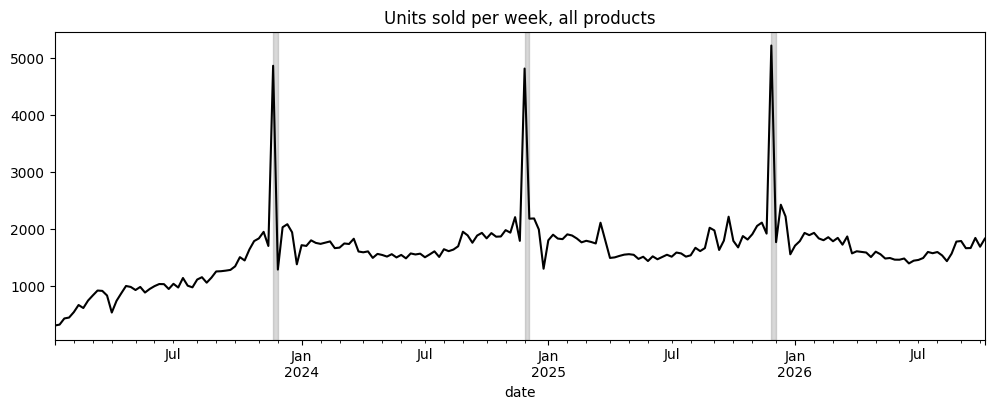

In [12]:
weekly = sales.set_index("date").units_sold.resample("W").sum()

ax = weekly.iloc[1:].plot(figsize=(12, 4), color="black", title="Units sold per week, all products")
for year in [2023, 2024, 2025]:
    ax.axvspan(bw_days[year][0], bw_days[year][-1], color="grey", alpha=0.3)
plt.show()

- `resample("W").sum()` adds up the daily sales into weeks, so the chart is easier to read.
- The grey bands are Black Week. Every year, sales jump.
- I skip the first week (`iloc[1:]`): it only contains 1 January 2023, which was a Sunday, so it looks artificially low.

In [13]:
for year in [2023, 2024, 2025]:
    units = sales[sales.date.isin(bw_days[year])].units_sold.sum()
    print(year, f"{units:,} units in Black Week")

2023 5,385 units in Black Week
2024 5,491 units in Black Week


2025 5,892 units in Black Week


Black Week sells around 5,500 units in total, and it's growing slightly each year.

## 3. Two problems in the data

Before building anything, I looked for things that could fool a forecast. I found two that matter a lot.

### Problem 1: Zero sales because the shelf was empty

When I looked at single products, I noticed sales sometimes drop to zero right after Black Week. The `stockout_flag` column explains why: the product had **sold out**.

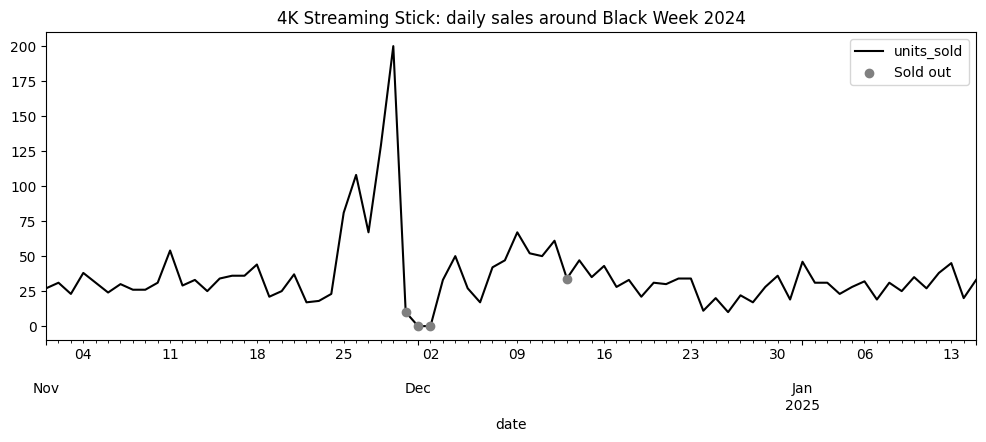

In [14]:
one = sales[sales.sku == "SKU015"].set_index("date")
one = one.loc["2024-11-01":"2025-01-15"]
empty = one[one.stockout_flag == 1]

ax = one.units_sold.plot(figsize=(12, 4), color="black", title="4K Streaming Stick: daily sales around Black Week 2024")
ax.scatter(empty.index, empty.units_sold, color="grey", zorder=3, label="Sold out")
ax.legend()
plt.show()

In [15]:
one.loc["2024-11-28":"2024-12-12", ["units_sold", "stock_end_of_day", "stockout_flag"]]

,units_sold,stock_end_of_day,stockout_flag
date,,,
2024-11-28,129,210,0
2024-11-29,200,10,0
2024-11-30,10,0,1
2024-12-01,0,0,1
2024-12-02,0,0,1
2024-12-03,33,447,0
2024-12-04,50,397,0
2024-12-05,27,370,0
2024-12-06,17,353,0


A few days after Black Friday, stock hits zero and sales stay at zero until new stock arrives. How often does this happen?

In [16]:
for year in [2023, 2024, 2025]:
    week = sales[sales.date.isin(bw_days[year])]
    n = week.groupby("sku").stockout_flag.max().sum()
    print(year, n, "products sold out during Black Week")

2023 9 products sold out during Black Week
2024 11 products sold out during Black Week
2025 13 products sold out during Black Week


`groupby("sku").stockout_flag.max()` gives 1 for every product that sold out on at least one day, and 0 for the others. `.sum()` counts the 1s.

**Why this is a problem:** a zero on a sold-out day doesn't mean nobody wanted the product. It means there was nothing to sell. If a model learns from those zeros, it thinks demand was low, and forecasts too little.

**What I do:** I remove sold-out days before the model learns. Prophet copes with missing days without problems. This isn't a regressor: it's **cleaning the data**, and it comes first.

### Problem 2: The discount changes from year to year

The same product doesn't always get the same Black Week discount:

In [17]:
discounts = pd.DataFrame()
for year in [2023, 2024, 2025]:
    week = sales[sales.date.isin(bw_days[year])]
    discounts[year] = week.groupby("sku").discount_pct.max() * 100

discounts.loc[["SKU026", "SKU036", "SKU028"]]

,2023,2024,2025
sku,,,
SKU026,25.0,20.0,0.0
SKU036,0.0,0.0,20.0
SKU028,5.0,20.0,20.0


One product had 25% off in 2023 and **no discount at all** in 2025. Another went from 0% to 20%.

**Why this is a problem:** the planner's usual shortcut, "same as last year", quietly assumes the same discount as last year. If the discount changes, sales change too.

**What I do:** I give the model the discount as a regressor, so it can learn how much the discount moves sales.

## 4. Which products can I forecast?

A model can only learn the Black Week effect if it has seen Black Weeks. So I keep products that:
- were on sale during **all three** past Black Weeks, and
- are **still on sale** today.

In [18]:
in_bw_2023 = sales.date.isin(bw_2023_days)
in_bw_2024 = sales.date.isin(bw_2024_days)
in_bw_2025 = sales.date.isin(bw_2025_days)
bw_sales = sales[in_bw_2023 | in_bw_2024 | in_bw_2025]

`|` means **or**: `bw_sales` contains all sales rows from any of the three past Black Weeks.

In [19]:
days_on_sale = bw_sales.groupby("sku").date.nunique()
full_history = days_on_sale[days_on_sale == 24].index

Three Black Weeks of 8 days make 24 days. I keep products that were on sale on all 24.

In [20]:
scope = products[products.sku.isin(full_history) & products.end_of_life_date.isna()]
print(len(scope), "products to forecast")
scope[["sku", "product_name", "category"]]

21 products to forecast


,sku,product_name,category
5,SKU006,Portable Bluetooth Speaker,Audio
10,SKU011,Fitness Band,Wearables
14,SKU015,4K Streaming Stick,TV & Smart Home
19,SKU020,Video Doorbell,TV & Smart Home
20,SKU021,Indoor Security Camera,TV & Smart Home
21,SKU022,Smart Plug 2-Pack,TV & Smart Home
22,SKU023,Wireless Game Controller,Gaming
25,SKU026,Mechanical Keyboard,Gaming
26,SKU027,Gaming Mouse,Gaming
27,SKU028,E-Reader,Computing & Mobile


`&` means **and**: the product had all 24 days, **and** it has no end-of-life date, so it's still on sale.

The other products are newer launches, or were discontinued. Newer products would need a different approach, for example using the sales history of the model they replaced.

## 5. Prepare the regressors

### Events

Prophet needs events in a table with four columns:
- `holiday`: the event's name
- `ds`: the day it starts
- `lower_window`: days before the start that also count (0 for me)
- `upper_window`: how many days it continues after the start

I make two tables: one with only Black Week, and one with all promotions. That way I can test them separately.

In [21]:
black_week_events = pd.DataFrame({
    "holiday": "black_week",
    "ds": black_week.start_date,
    "lower_window": 0,
    "upper_window": 7,
})
black_week_events

,holiday,ds,lower_window,upper_window
year,,,,
2023,black_week,2023-11-20,0,7
2024,black_week,2024-11-25,0,7
2025,black_week,2025-11-24,0,7
2026,black_week,2026-11-23,0,7


An upper window of 7 means Black Week continues 7 days after the Monday it starts: 8 days in total. Because of the window, Prophet learns a **separate effect for each of the 8 days**, so Black Friday and Cyber Monday can be bigger than the Tuesday.

In [22]:
others = calendar[calendar.event != "Black Week"]

other_events = pd.DataFrame({
    "holiday": "other_promotion",
    "ds": others.start_date,
    "lower_window": 0,
    "upper_window": (others.end_date - others.start_date).dt.days,
})

all_events = pd.concat([black_week_events, other_events])
print(len(all_events), "events in total")

24 events in total


The other promotions have different lengths (Singles Day is one day, Back to School two weeks), so their window comes from their own start and end dates. `pd.concat` stacks the two tables into one.

### Numbers: the discount

The discount for every product and every day is already in the sales data, in `discount_pct`. For the past, there's nothing to prepare. For the future, I'll use marketing's promotion plan (section 10).

### Prophet's format

Prophet only accepts a table with a date column called `ds` and the value to forecast called `y`. Here's one product as an example:

In [23]:
df = sales[sales.sku == "SKU015"].rename(columns={"date": "ds", "units_sold": "y"})
df[["ds", "y", "discount_pct", "stockout_flag"]].head()

,ds,y,discount_pct,stockout_flag
8147,2023-01-01,19,0.0,0
8148,2023-01-02,31,0.0,0
8149,2023-01-03,29,0.0,0
8150,2023-01-04,37,0.0,0
8151,2023-01-05,34,0.0,0


## 6. The benchmark: same as last year

Before using any model, I need something simple to compare it with. The simplest forecast a planner can make: **this Black Week will sell the same as last Black Week.**

If my model can't beat that, it isn't worth using.

### How I test

I go back in time. I pretend it's **12 October** of a past year, make a forecast with only the data available then, and compare it with what really sold in that year's Black Week.

I test on **two years, 2024 and 2025**, because one year could be luck.

First, I build the test table: for each year and product, last year's Black Week sales, the actual sales, and whether the product sold out during the test week.

In [24]:
results = []

for year in [2024, 2025]:
    for sku in scope.sku:
        df = sales[sales.sku == sku]
        last_year = df[df.date.isin(bw_days[year - 1])]
        actual = df[df.date.isin(bw_days[year])]

        results.append([year, sku, last_year.units_sold.sum(), actual.units_sold.sum(), actual.stockout_flag.sum()])

test_results = pd.DataFrame(results, columns=["year", "sku", "last_year", "actual", "sold_out_days"])
test_results.head()

,year,sku,last_year,actual,sold_out_days
0,2024,SKU006,296,448,0
1,2024,SKU011,256,230,3
2,2024,SKU015,776,595,3
3,2024,SKU020,73,71,0
4,2024,SKU021,140,90,1


21 products × 2 years = 42 rows. Now I add the forecasts, one step at a time.

## 7. The test: what is each regressor worth?

I build five versions of the forecast. Each one knows one thing more than the one before:

| Step | What the model knows |
|---|---|
| 0 | Past sales only |
| 1 | Past sales, without the sold-out days |
| 2 | + Black Week as an event |
| 3 | + the other promotions as events |
| 4 | + the discount |

The pattern is the same in every step:
1. Take one product's sales, in Prophet's format.
2. Keep only the days before 12 October of the test year (`train`).
3. Let Prophet learn from them (`fit`).
4. Make a list of dates up to the end of the year (`make_future_dataframe`) and forecast them (`predict`).
5. Add up the forecast for the 8 Black Week days.

**Two details:**
- `periods=81`: the training data ends on 11 October. 81 more days take me to 31 December, which covers Black Week.
- `yhat` is Prophet's forecast. `.clip(lower=0)` turns negative forecasts into 0: for slow-selling products, Prophet sometimes predicts slightly below zero, which makes no sense for sales.

⏳ Each step trains 42 models, so each cell takes a few seconds.

### Step 0: Past sales only

In [25]:
step0 = []

for year, sku in zip(test_results.year, test_results.sku):
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
    train = df[df.ds < f"{year}-10-12"]

    model = Prophet()
    model.fit(train[["ds", "y"]])
    future = model.make_future_dataframe(periods=81)
    forecast = model.predict(future)

    step0.append(forecast[forecast.ds.isin(bw_days[year])].yhat.clip(lower=0).sum())

test_results["step0"] = step0

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


`zip` walks through two columns side by side: for every row, I get its year and its product.

### Step 1: Without the sold-out days

The only change: `train` keeps days **before the cutoff** *and* **not sold out**.

In [26]:
step1 = []

for year, sku in zip(test_results.year, test_results.sku):
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
    train = df[(df.ds < f"{year}-10-12") & (df.stockout_flag == 0)]

    model = Prophet()
    model.fit(train[["ds", "y"]])
    future = model.make_future_dataframe(periods=81)
    forecast = model.predict(future)

    step1.append(forecast[forecast.ds.isin(bw_days[year])].yhat.clip(lower=0).sum())

test_results["step1"] = step1

### Step 2: + Black Week as an event

Now Prophet gets the Black Week dates: `Prophet(holidays=black_week_events)`.

In [27]:
step2 = []

for year, sku in zip(test_results.year, test_results.sku):
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
    train = df[(df.ds < f"{year}-10-12") & (df.stockout_flag == 0)]

    model = Prophet(holidays=black_week_events)
    model.fit(train[["ds", "y"]])
    future = model.make_future_dataframe(periods=81)
    forecast = model.predict(future)

    step2.append(forecast[forecast.ds.isin(bw_days[year])].yhat.clip(lower=0).sum())

test_results["step2"] = step2

### Step 3: + the other promotions

In [28]:
step3 = []

for year, sku in zip(test_results.year, test_results.sku):
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
    train = df[(df.ds < f"{year}-10-12") & (df.stockout_flag == 0)]

    model = Prophet(holidays=all_events)
    model.fit(train[["ds", "y"]])
    future = model.make_future_dataframe(periods=81)
    forecast = model.predict(future)

    step3.append(forecast[forecast.ds.isin(bw_days[year])].yhat.clip(lower=0).sum())

test_results["step3"] = step3

### Step 4: + the discount

Two new things:
- `model.add_regressor("discount_pct")` tells Prophet to also learn how the discount affects sales. The training table now needs the `discount_pct` column too.
- The future dates also need a discount, so I add it with `merge`. For the test week, that's the discount that was planned for that Black Week: a planner would have known it in October.

In [29]:
step4 = []

for year, sku in zip(test_results.year, test_results.sku):
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
    train = df[(df.ds < f"{year}-10-12") & (df.stockout_flag == 0)]

    model = Prophet(holidays=all_events)
    model.add_regressor("discount_pct")
    model.fit(train[["ds", "y", "discount_pct"]])

    future = model.make_future_dataframe(periods=81)
    future = future.merge(df[["ds", "discount_pct"]], on="ds", how="left")
    forecast = model.predict(future)

    step4.append(forecast[forecast.ds.isin(bw_days[year])].yhat.clip(lower=0).sum())

test_results["step4"] = step4
test_results.head()

,year,sku,last_year,actual,sold_out_days,step0,step1,step2,step3,step4
0,2024,SKU006,296,448,0,62.251744,69.783030,283.050786,282.591439,284.002167
1,2024,SKU011,256,230,3,73.240695,70.544092,188.261668,183.833969,188.733826
2,2024,SKU015,776,595,3,191.967264,204.403021,789.642244,783.651551,866.571262
3,2024,SKU020,73,71,0,33.478516,33.478516,66.998212,65.919357,64.250720
4,2024,SKU021,140,90,1,48.430684,48.806319,127.064248,127.597069,129.276074


## 8. Measuring the results fairly

### Only products that didn't sell out in the test week

Some products sold out *during* the Black Week I'm testing on. Their "actual" sales are lower than real demand. A good forecast would wrongly look too high next to them.

So I only compare on products that **did not sell out** in the test week.

In [30]:
fair = test_results[test_results.sold_out_days == 0].copy()   # .copy() = a separate table I can add columns to

print(len(fair[fair.year == 2024]), "products in 2024")
print(len(fair[fair.year == 2025]), "products in 2025")

16 products in 2024
16 products in 2025


### How I measure the error

For each product, I calculate how many units the forecast was off, whether too high or too low. Then I add up all those misses and divide by the total actual sales. This is called **WAPE** (weighted absolute percentage error).

**A small example:** I forecast 100 and 50 units for two products. They actually sold 90 and 60. The misses are 10 + 10 = 20 units. Total actual sales: 150. Error: 20 / 150 = **13%**.

Lower is better. I use WAPE because big products count more than tiny ones, which matches what matters for stock planning.

In [31]:
methods = ["last_year", "step0", "step1", "step2", "step3", "step4"]

for m in methods:
    fair["miss_" + m] = abs(fair[m] - fair.actual)

fair[["year", "sku", "actual", "step4", "miss_step4"]].head()

,year,sku,actual,step4,miss_step4
0,2024,SKU006,448,284.002167,163.997833
3,2024,SKU020,71,64.250720,6.749280
5,2024,SKU022,488,523.816629,35.816629
7,2024,SKU026,76,86.746343,10.746343
8,2024,SKU027,91,84.503822,6.496178


In [32]:
errors = pd.DataFrame()

for year in [2024, 2025]:
    t = fair[fair.year == year]
    row = []
    for m in methods:
        row.append(round(t["miss_" + m].sum() / t.actual.sum() * 100))
    errors[year] = row

errors.index = ["Same as last year", "0. Past sales only", "1. Without sold-out days",
                "2. + Black Week event", "3. + other promotions", "4. + discount"]
errors

,2024,2025
Same as last year,22,11
0. Past sales only,63,34
1. Without sold-out days,62,28
2. + Black Week event,22,12
3. + other promotions,22,12
4. + discount,15,12


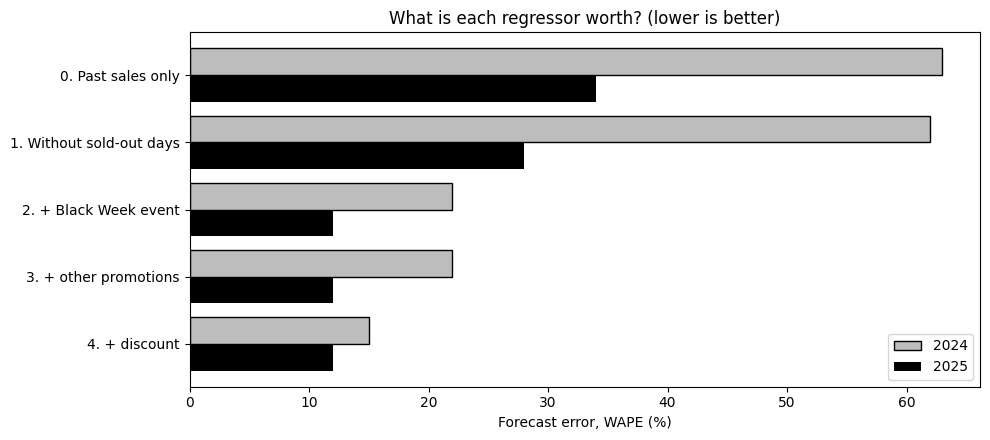

In [33]:
steps = errors.drop("Same as last year").iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(steps))
ax.barh(y + 0.2, steps[2024], height=0.4, color="#BDBDBD", edgecolor="black", label="2024")
ax.barh(y - 0.2, steps[2025], height=0.4, color="black", label="2025")
ax.set_yticks(y)
ax.set_yticklabels(steps.index)
ax.set_xlabel("Forecast error, WAPE (%)")
ax.set_title("What is each regressor worth? (lower is better)")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/chart_regressor_steps.png", dpi=150)
plt.show()

### What I learn from this

A word of caution first: only 16 products per year count in the fair test. Differences of one or two points could be chance. The big differences are the ones to trust.

1. **Past sales alone don't work for Black Week.** The model misses a large part of the volume, because nothing in the sales history tells it *"this week is special"*.
2. **Removing sold-out days helps a little**, but it doesn't fix the main problem.
3. **The Black Week event is the big step.** Once the model knows when Black Week is, it's about as good as "same as last year".
4. **The other promotions add almost nothing** for this question. That's useful too: not every regressor earns its place, which is why I tested each one.
5. **The discount helps when it changes.** In 2024 it clearly lowered the error. In 2025 it made little difference.

## 9. My decision

"Same as last year" and the full model (step 4) are now close. But they make **different kinds of mistakes**:
- Last year copies whatever happened last year, including bad luck like a stockout.
- The model learns from all years, but it has seen very few Black Weeks.

When two forecasts make different mistakes, averaging them often cancels some out. So I test one more version: **the average of both**.

In [34]:
fair["combined"] = (fair.last_year + fair.step4) / 2
fair["miss_combined"] = abs(fair.combined - fair.actual)

for year in [2024, 2025]:
    t = fair[fair.year == year]
    for m in ["last_year", "step4", "combined"]:
        error = t["miss_" + m].sum() / t.actual.sum() * 100
        print(year, m, f"{error:.0f}%")
    print()

2024 last_year 22%
2024 step4 15%
2024 combined 18%

2025 last_year 11%
2025 step4 12%
2025 combined 8%



The combined forecast is the **most reliable across both years**: never the worst, and the best in 2025. In 2024, the model alone did a bit better.

**My choice:** the average of **same as last year** (the planner's view) and **Prophet with Black Week, promotions and the planned discount** (the model's view).

**Why a simple 50/50 average, and not 70/30?** With only two test years, I can't tell which weights are really better. Tuning them would just fit this data. A 50/50 average has nothing to tune, so it's the honest choice.

### How sure am I? A planning range

One number isn't enough to plan stock. So I look at how far off the combined forecast was in the test. For each product, I divide actual sales by the forecast:
- 1.00 means perfect,
- 0.80 means actual sales were 20% lower,
- 1.20 means they were 20% higher.

`np.percentile(ratio, [10, 90])` gives me the two values that 8 out of 10 results fall between.

In [35]:
ratio = fair.actual / fair.combined
low_factor, high_factor = np.percentile(ratio, [10, 90])

print(f"Low factor:  {low_factor:.2f}")
print(f"High factor: {high_factor:.2f}")

Low factor:  0.71
High factor: 1.19


For 2026: **low = forecast × low factor**, and **high = forecast × high factor**.

One caveat: these factors come from the same test I used to choose the method, so the range may be a little too optimistic. I'll know after Black Week 2026.

## 10. Forecast Black Week 2026

Same method, now with all sales up to **12 October 2026**.

The one difference: for future days, the discount doesn't come from the sales data (those days haven't happened yet). It comes from **marketing's promotion plan**:

In [36]:
promo_plan[promo_plan.event == "Black Week"].head()

,event,sku,start_date,end_date,discount_pct
15,Black Week,SKU003,2026-11-23,2026-11-30,0.10
16,Black Week,SKU005,2026-11-23,2026-11-30,0.15
17,Black Week,SKU006,2026-11-23,2026-11-30,0.35
18,Black Week,SKU007,2026-11-23,2026-11-30,0.25
19,Black Week,SKU010,2026-11-23,2026-11-30,0.30


For each product, I build the list of future days, start with 0% discount everywhere, and then write in the planned discount for each promotion of that product. `between(start, end)` selects the days from start to end, both included.

In [37]:
plan = []
daily = []

for sku in scope.sku:
    df = sales[sales.sku == sku].rename(columns={"date": "ds", "units_sold": "y"})
    train = df[(df.ds < "2026-10-12") & (df.stockout_flag == 0)]

    model = Prophet(holidays=all_events)
    model.add_regressor("discount_pct")
    model.fit(train[["ds", "y", "discount_pct"]])

    future = model.make_future_dataframe(periods=81)
    future = future.merge(df[["ds", "discount_pct"]], on="ds", how="left")
    future["discount_pct"] = future.discount_pct.fillna(0)
    for row in promo_plan[promo_plan.sku == sku].itertuples():
        future.loc[future.ds.between(row.start_date, row.end_date), "discount_pct"] = row.discount_pct

    forecast = model.predict(future)
    forecast_bw = forecast[forecast.ds.isin(bw_2026_days)]

    last_year = df[df.ds.isin(bw_2025_days)]
    discount_2026 = future[future.ds.isin(bw_2026_days)].discount_pct.max()

    plan.append([
        sku,
        last_year.y.sum(),
        forecast_bw.yhat.clip(lower=0).sum(),
        last_year.stockout_flag.sum() > 0,
        last_year.discount_pct.max() * 100,
        discount_2026 * 100,
    ])
    daily.append(forecast_bw[["ds", "yhat"]].assign(sku=sku))

plan = pd.DataFrame(plan, columns=["sku", "last_year", "model", "sold_out_last_year", "discount_2025", "discount_2026"])
plan.head()

,sku,last_year,model,sold_out_last_year,discount_2025,discount_2026
0,SKU006,456,442.804929,False,30.0,35.0
1,SKU011,260,344.365093,True,30.0,20.0
2,SKU015,657,876.396312,True,25.0,30.0
3,SKU020,63,71.234803,False,10.0,0.0
4,SKU021,108,100.752702,False,15.0,0.0


- `fillna(0)`: future days without any value get 0% discount.
- `itertuples()` goes through the promotion plan one row at a time, so each planned promotion is written onto its dates.
- I also keep the daily forecast (`daily`), to see which days will be busiest.

Now I apply my method: the average of last year and the model, plus the planning range.

In [38]:
plan["forecast"] = (plan.last_year + plan.model) / 2
plan["low"] = plan.forecast * low_factor
plan["high"] = plan.forecast * high_factor
plan.head()

,sku,last_year,model,sold_out_last_year,discount_2025,discount_2026,forecast,low,high
0,SKU006,456,442.804929,False,30.0,35.0,449.402465,321.195408,534.226286
1,SKU011,260,344.365093,True,30.0,20.0,302.182546,215.974886,359.218901
2,SKU015,657,876.396312,True,25.0,30.0,766.698156,547.971910,911.410907
3,SKU020,63,71.234803,False,10.0,0.0,67.117401,47.969922,79.785677
4,SKU021,108,100.752702,False,15.0,0.0,104.376351,74.599512,124.077180


### Notes for the planning team

Some products need extra attention, so I add a note:
- **Bigger or smaller discount than last year:** sales will probably move in the same direction.
- **Sold out last year:** last year's sales were held back by stock, so real demand was higher. Since "last year" is half of my forecast, it's probably on the low side for these products: plan towards the high end of the range.

In [39]:
plan["note"] = ""
plan.loc[plan.discount_2026 > plan.discount_2025, "note"] = "Bigger discount than last year"
plan.loc[plan.discount_2026 < plan.discount_2025, "note"] = "Smaller discount than last year"
plan.loc[plan.sold_out_last_year, "note"] = plan.note + "; Sold out last year: plan towards the high end"
plan["note"] = plan.note.str.strip("; ")

print(plan.sold_out_last_year.sum(), "products sold out last year")
print((plan.discount_2026 != plan.discount_2025).sum(), "products have a different discount than last year")

5 products sold out last year
15 products have a different discount than last year


## 11. The demand plan for the client

This is what I'd hand to the planning team: one row per product, sorted from the biggest seller down.

In [40]:
demand_plan = plan.merge(products[["sku", "product_name", "category"]], on="sku")
demand_plan = demand_plan[["product_name", "category", "forecast", "low", "high",
                           "last_year", "discount_2025", "discount_2026", "note"]]
demand_plan[["forecast", "low", "high"]] = demand_plan[["forecast", "low", "high"]].round(0).astype(int)
demand_plan = demand_plan.sort_values("forecast", ascending=False)

demand_plan.to_csv("../outputs/black_week_2026_demand_plan.csv", index=False)
demand_plan

,product_name,category,forecast,low,high,last_year,discount_2025,discount_2026,note
2,4K Streaming Stick,TV & Smart Home,767,548,911,657,25.0,30.0,Bigger discount than last year; Sold out last ...
0,Portable Bluetooth Speaker,Audio,449,321,534,456,30.0,35.0,Bigger discount than last year
5,Smart Plug 2-Pack,TV & Smart Home,413,295,491,348,25.0,25.0,Sold out last year: plan towards the high end
6,Wireless Game Controller,Gaming,310,222,369,261,25.0,35.0,Bigger discount than last year; Sold out last ...
1,Fitness Band,Wearables,302,216,359,260,30.0,20.0,Smaller discount than last year; Sold out last...
11,USB-C Cable 2m,Computing & Mobile,262,187,311,258,25.0,20.0,Smaller discount than last year
9,E-Reader,Computing & Mobile,261,187,311,243,20.0,15.0,Smaller discount than last year; Sold out last...
10,USB-C Charger 65W,Computing & Mobile,179,128,213,171,15.0,20.0,Bigger discount than last year
13,Universal Phone Case,Computing & Mobile,167,120,199,154,15.0,25.0,Bigger discount than last year
12,"Power Bank 20,000 mAh",Computing & Mobile,125,89,149,126,20.0,10.0,Smaller discount than last year


In [41]:
total = demand_plan[["forecast", "low", "high", "last_year"]].sum()

print(f"Black Week 2026, {len(demand_plan)} products")
print(f"  Forecast:       {total.forecast:,.0f} units")
print(f"  Planning range: {total.low:,.0f} to {total.high:,.0f} units")
print(f"  Last year:      {total.last_year:,.0f} units")

Black Week 2026, 21 products
  Forecast:       3,793 units
  Planning range: 2,713 to 4,511 units
  Last year:      3,510 units


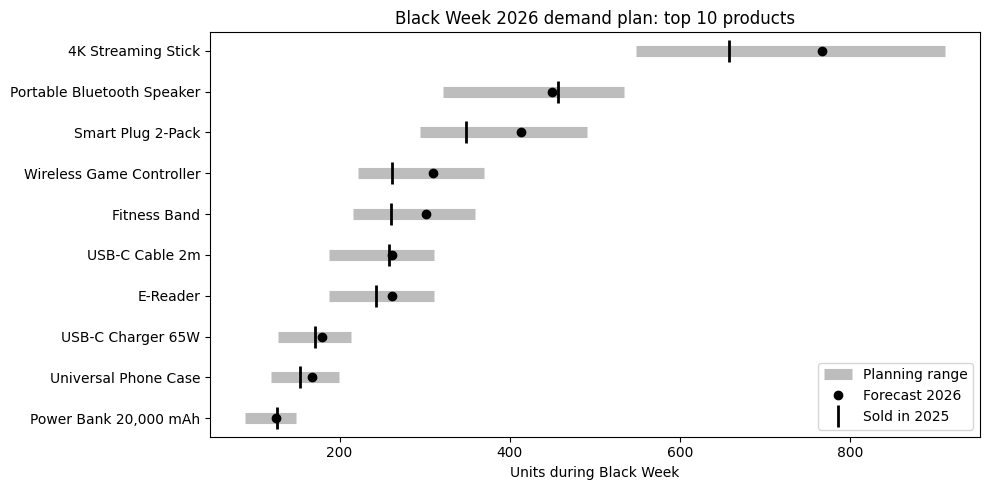

In [42]:
top = demand_plan.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hlines(top.product_name, top.low, top.high, color="#BDBDBD", lw=8, label="Planning range")
ax.plot(top.forecast, top.product_name, "o", color="black", label="Forecast 2026")
ax.plot(top.last_year, top.product_name, "|", color="black", ms=16, mew=2, label="Sold in 2025")
ax.set_xlabel("Units during Black Week")
ax.set_title("Black Week 2026 demand plan: top 10 products")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/chart_demand_plan_top10.png", dpi=150)
plt.show()

### Which days will be busiest?

For warehouse staff and customer service, it helps to know which days will be busiest. I take the model's day-by-day shape for each product and scale it to my combined forecast.

This is a **guide, not an exact plan**: how sales split between Friday, Saturday and Cyber Monday can shift from year to year.

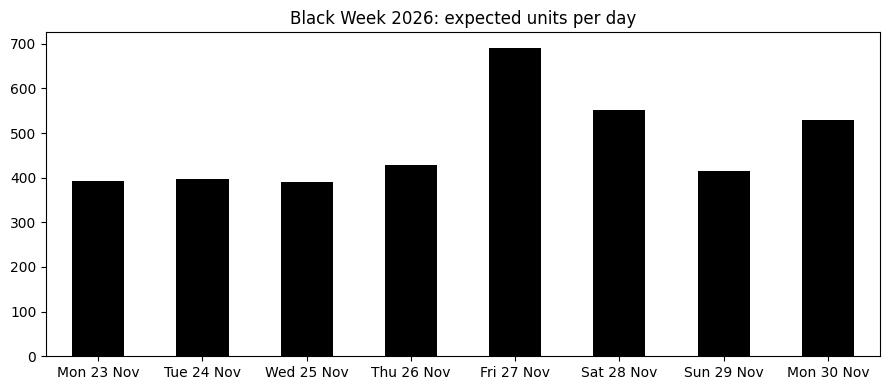

In [43]:
daily = pd.concat(daily)
daily["yhat"] = daily.yhat.clip(lower=0)
daily["share"] = daily.yhat / daily.groupby("sku").yhat.transform("sum")
daily = daily.merge(plan[["sku", "forecast"]], on="sku")
daily["units"] = daily.share * daily.forecast

per_day = daily.groupby("ds").units.sum().round(0)
per_day.index = per_day.index.strftime("%a %d %b")
per_day.to_csv("../outputs/black_week_2026_daily_profile.csv")

ax = per_day.plot(kind="bar", figsize=(9, 4), color="black", rot=0, title="Black Week 2026: expected units per day")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../outputs/chart_daily_profile.png", dpi=150)
plt.show()

- `share`: for each product, which part of its Black Week sales falls on each day (the 8 shares add up to 1).
- `units`: that share times my combined forecast.
- Black Friday is the peak, followed by Saturday and Cyber Monday.

## 12. Limitations and next steps

**Limitations**
- **Synthetic data.** I designed the effects, so the method finding them shows it works *as intended*, not that it works for a real shop.
- **Few Black Weeks to learn from.** At most three per product, and only one before the 2024 test.
- **Small test.** 16 products per year in the fair comparison. Small differences between methods may be chance.
- **The planning range isn't tested on new data yet.** It comes from the same years I used to choose the method.
- **The discount effect is learned from the past.** A much deeper discount than ever before, say 50%, would be a guess.
- **The calendar's promotions are shop-wide.** Not every product joins every promotion.
- **Sold-out days are removed, not estimated.** I don't estimate how much would have sold.
- **Established products only.** New products need another approach.

**Next steps**
1. Repeat the regressor test on real public data (M5, Walmart) to see which findings hold.
2. After Black Week 2026, compare the forecast with real sales, and check the planning range.
3. Estimate lost sales on sold-out days, instead of just removing them.
4. Turn the forecast into order quantities: how much stock to buy, given what overstock and stockouts cost.

## Summary

| | |
|---|---|
| **Question** | How many units will each product sell in Black Week 2026? |
| **Key insight** | A forecast needs to know what makes a week special: the event and the discount |
| **Method** | Average of "same as last year" and Prophet with Black Week, promotions and the planned discount |
| **Tested on** | Black Week 2024 and 2025, products that didn't sell out |
| **Deliverable** | Forecast, planning range and notes per product, plus the busiest days |

**What this project shows:** how to build a forecast step by step, test what each piece of information is worth, avoid unfair comparisons, and turn the result into something a planning team can use.

**What it doesn't show (yet):** that these exact improvements hold for a real shop. That needs real data.